# Fusion Architecture Ablation

This notebook compares different methods of fusing the Gold M signal with the Q vector.
- **Concat_M64**: Projects M to 64 dimensions and concatenates with Q.
- **Gated**: Uses M to generate a 0-1 gate to mask Q features.
- **FiLM_Scale**: Uses M directly as a scalar to scale Q features (1 + s*gamma).
- **FiLM_Full**: Uses M to both scale and shift Q features (1 + s*gamma)*Q + s*beta.

In [23]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('default')
sns.set_theme(style="white", palette="muted")
plt.rcParams['figure.dpi'] = 300

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

base_dir = Path('.')
paths = {
    'Concat (M=64)': base_dir / 'concat_m64/output/summary.json',
    'Gated': base_dir / 'gated_m64/output/summary.json',
    'FiLM (Scale)': base_dir / 'film_scale_m64/output/summary.json',
    'FiLM (Full)': base_dir / 'film_full_m64/output/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        data[name] = summary['aggregate'][0] # Only one config per family

print(f"Loaded {len(data)} architectures.")

Loaded 4 architectures.


,Fusion Architecture,Dev nDCG,Test nDCG
0,Concat (M=64),86.12,82.46
1,Gated,69.00,71.61
2,FiLM (Scale),69.79,72.13
3,FiLM (Full),86.27,80.72


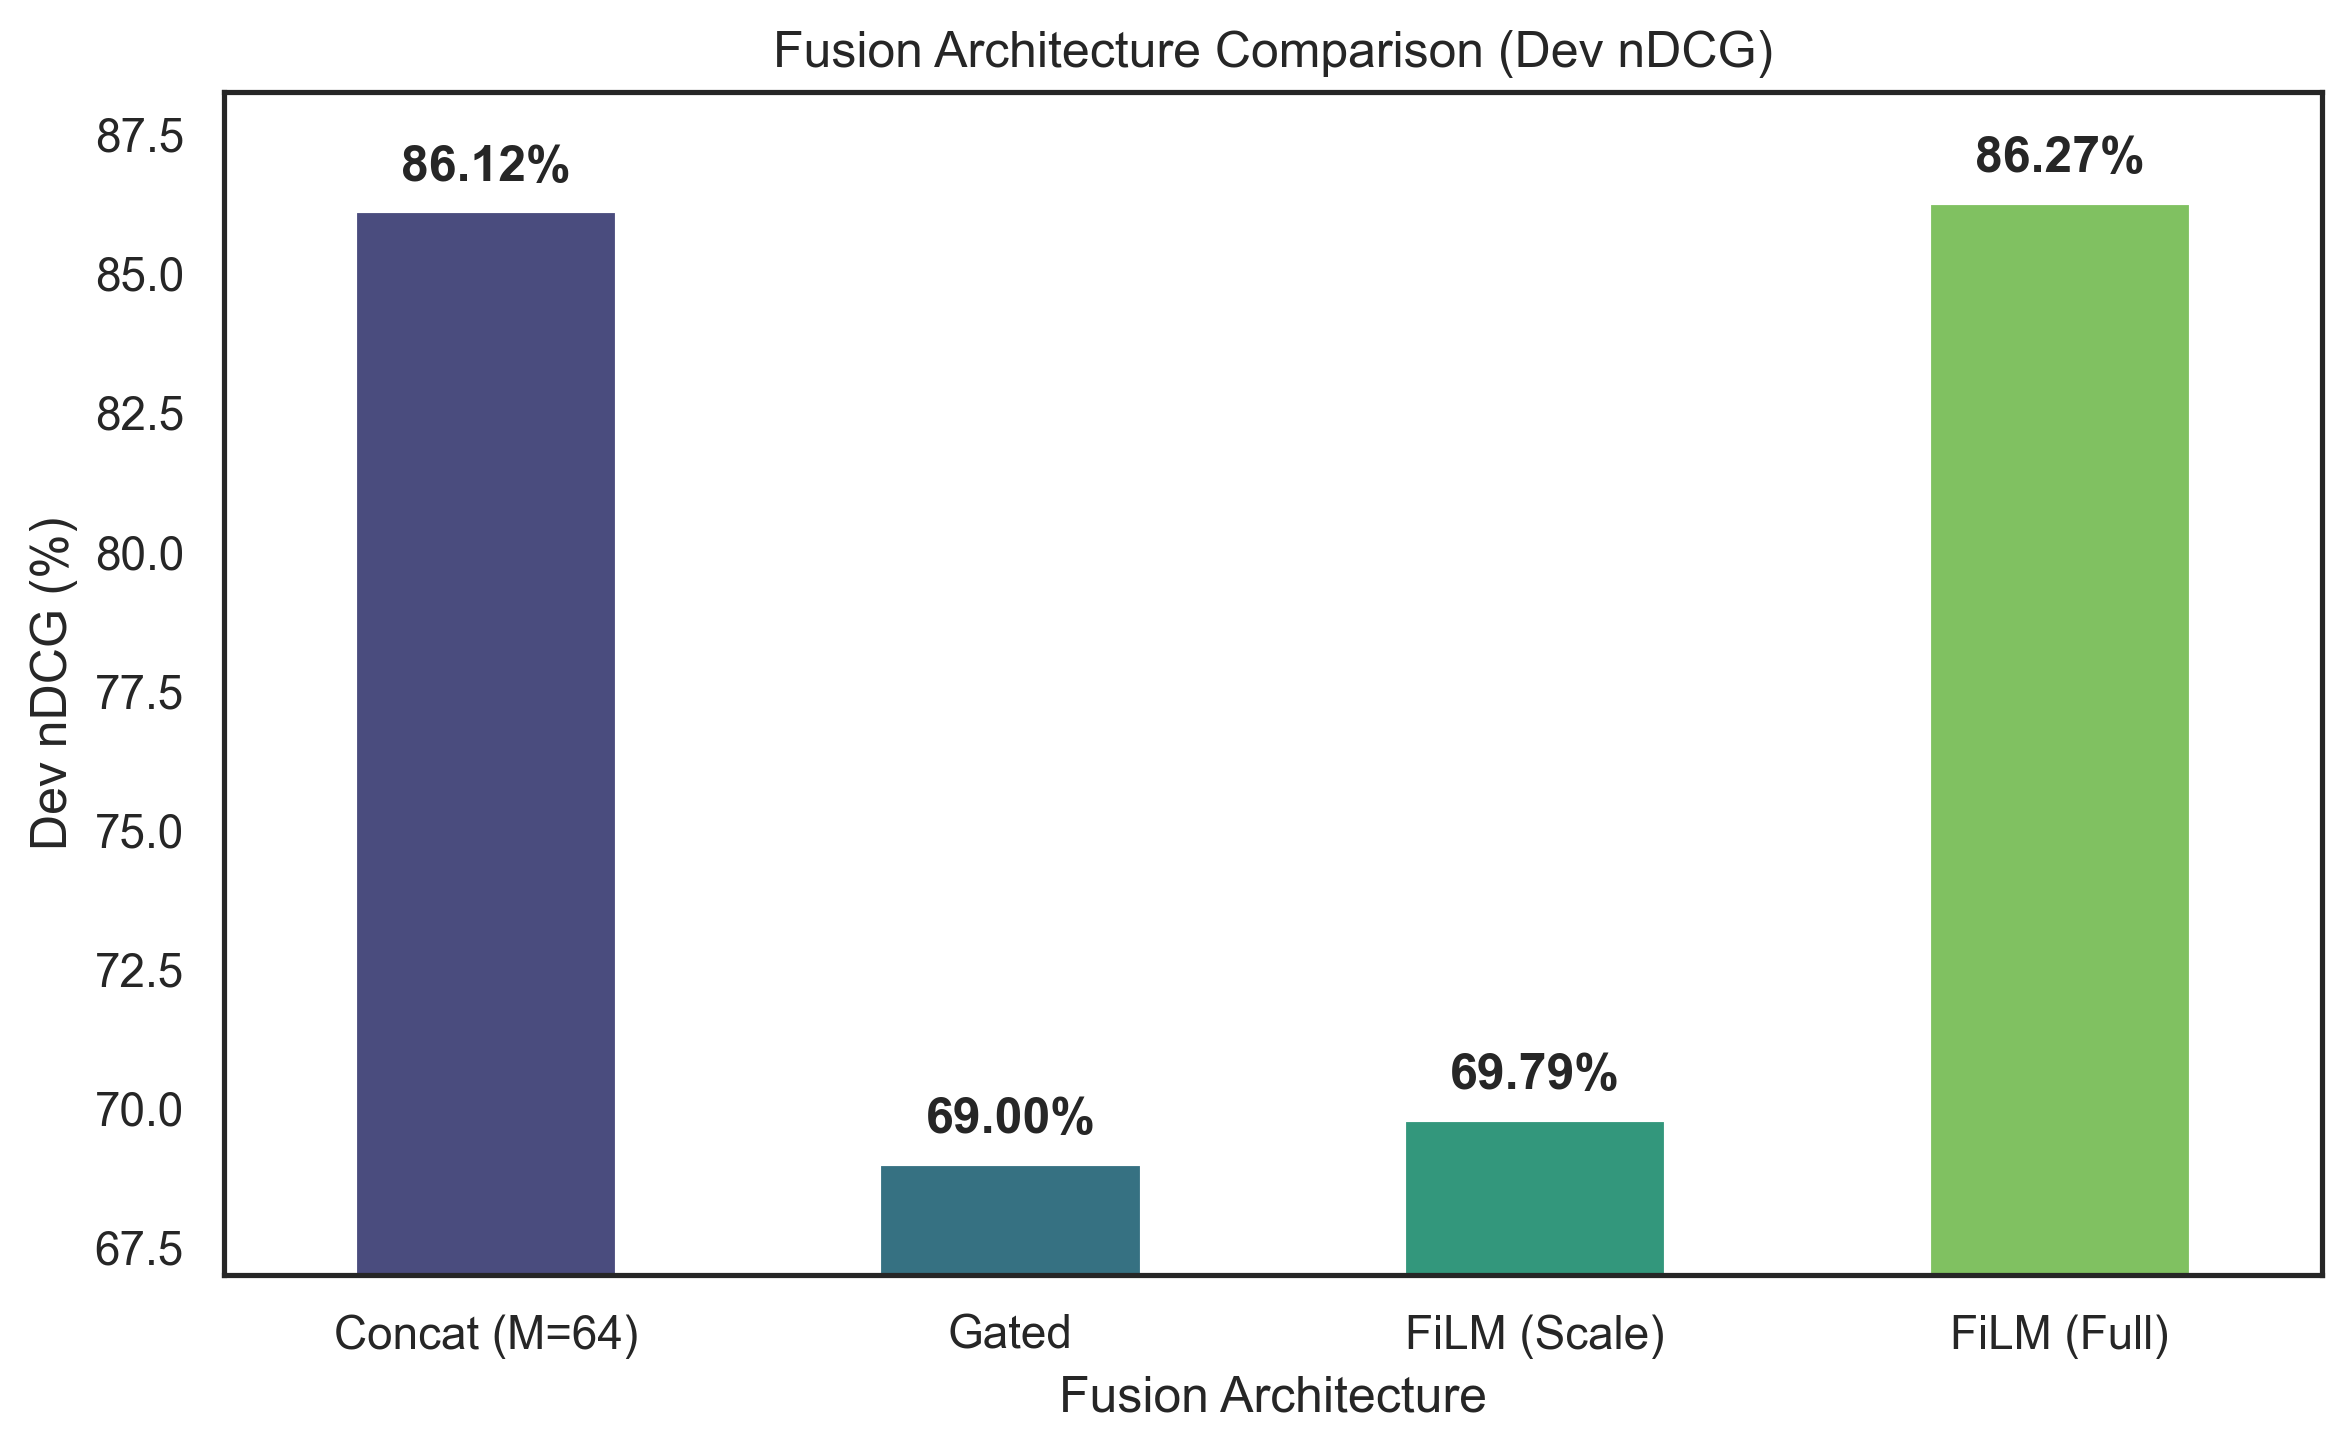

In [24]:
if len(data) > 0:
    rows = []
    for name, agg in data.items():
        rows.append({
            'Fusion Architecture': name,
            'Dev nDCG': agg['best_dev']['ndcg'] * 100,
            'Test nDCG': agg['test']['ndcg'] * 100
        })
    
    df = pd.DataFrame(rows)
    display(df.round(2))
    
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(data=df, x='Fusion Architecture', y='Dev nDCG', hue='Fusion Architecture', legend=False, palette='viridis', width=0.5)
    
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}%',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontweight='bold')
    
    min_val = df['Dev nDCG'].min()
    max_val = df['Dev nDCG'].max()
    plt.ylim(max(0, min_val - 2), min(100, max_val + 2))
    plt.title('Fusion Architecture Comparison (Dev nDCG)')
    plt.ylabel('Dev nDCG (%)')
    plt.tight_layout()
    plt.show()
else:
    print("No data found. Please run the experiments first.")

,Architecture,Dev nDCG,Xeval nDCG
0,Concat (M=64),86.123731,80.113580
1,Gated,69.002295,74.769478
2,FiLM (Scale),69.793882,75.138770
3,FiLM (Full),86.268824,81.505285


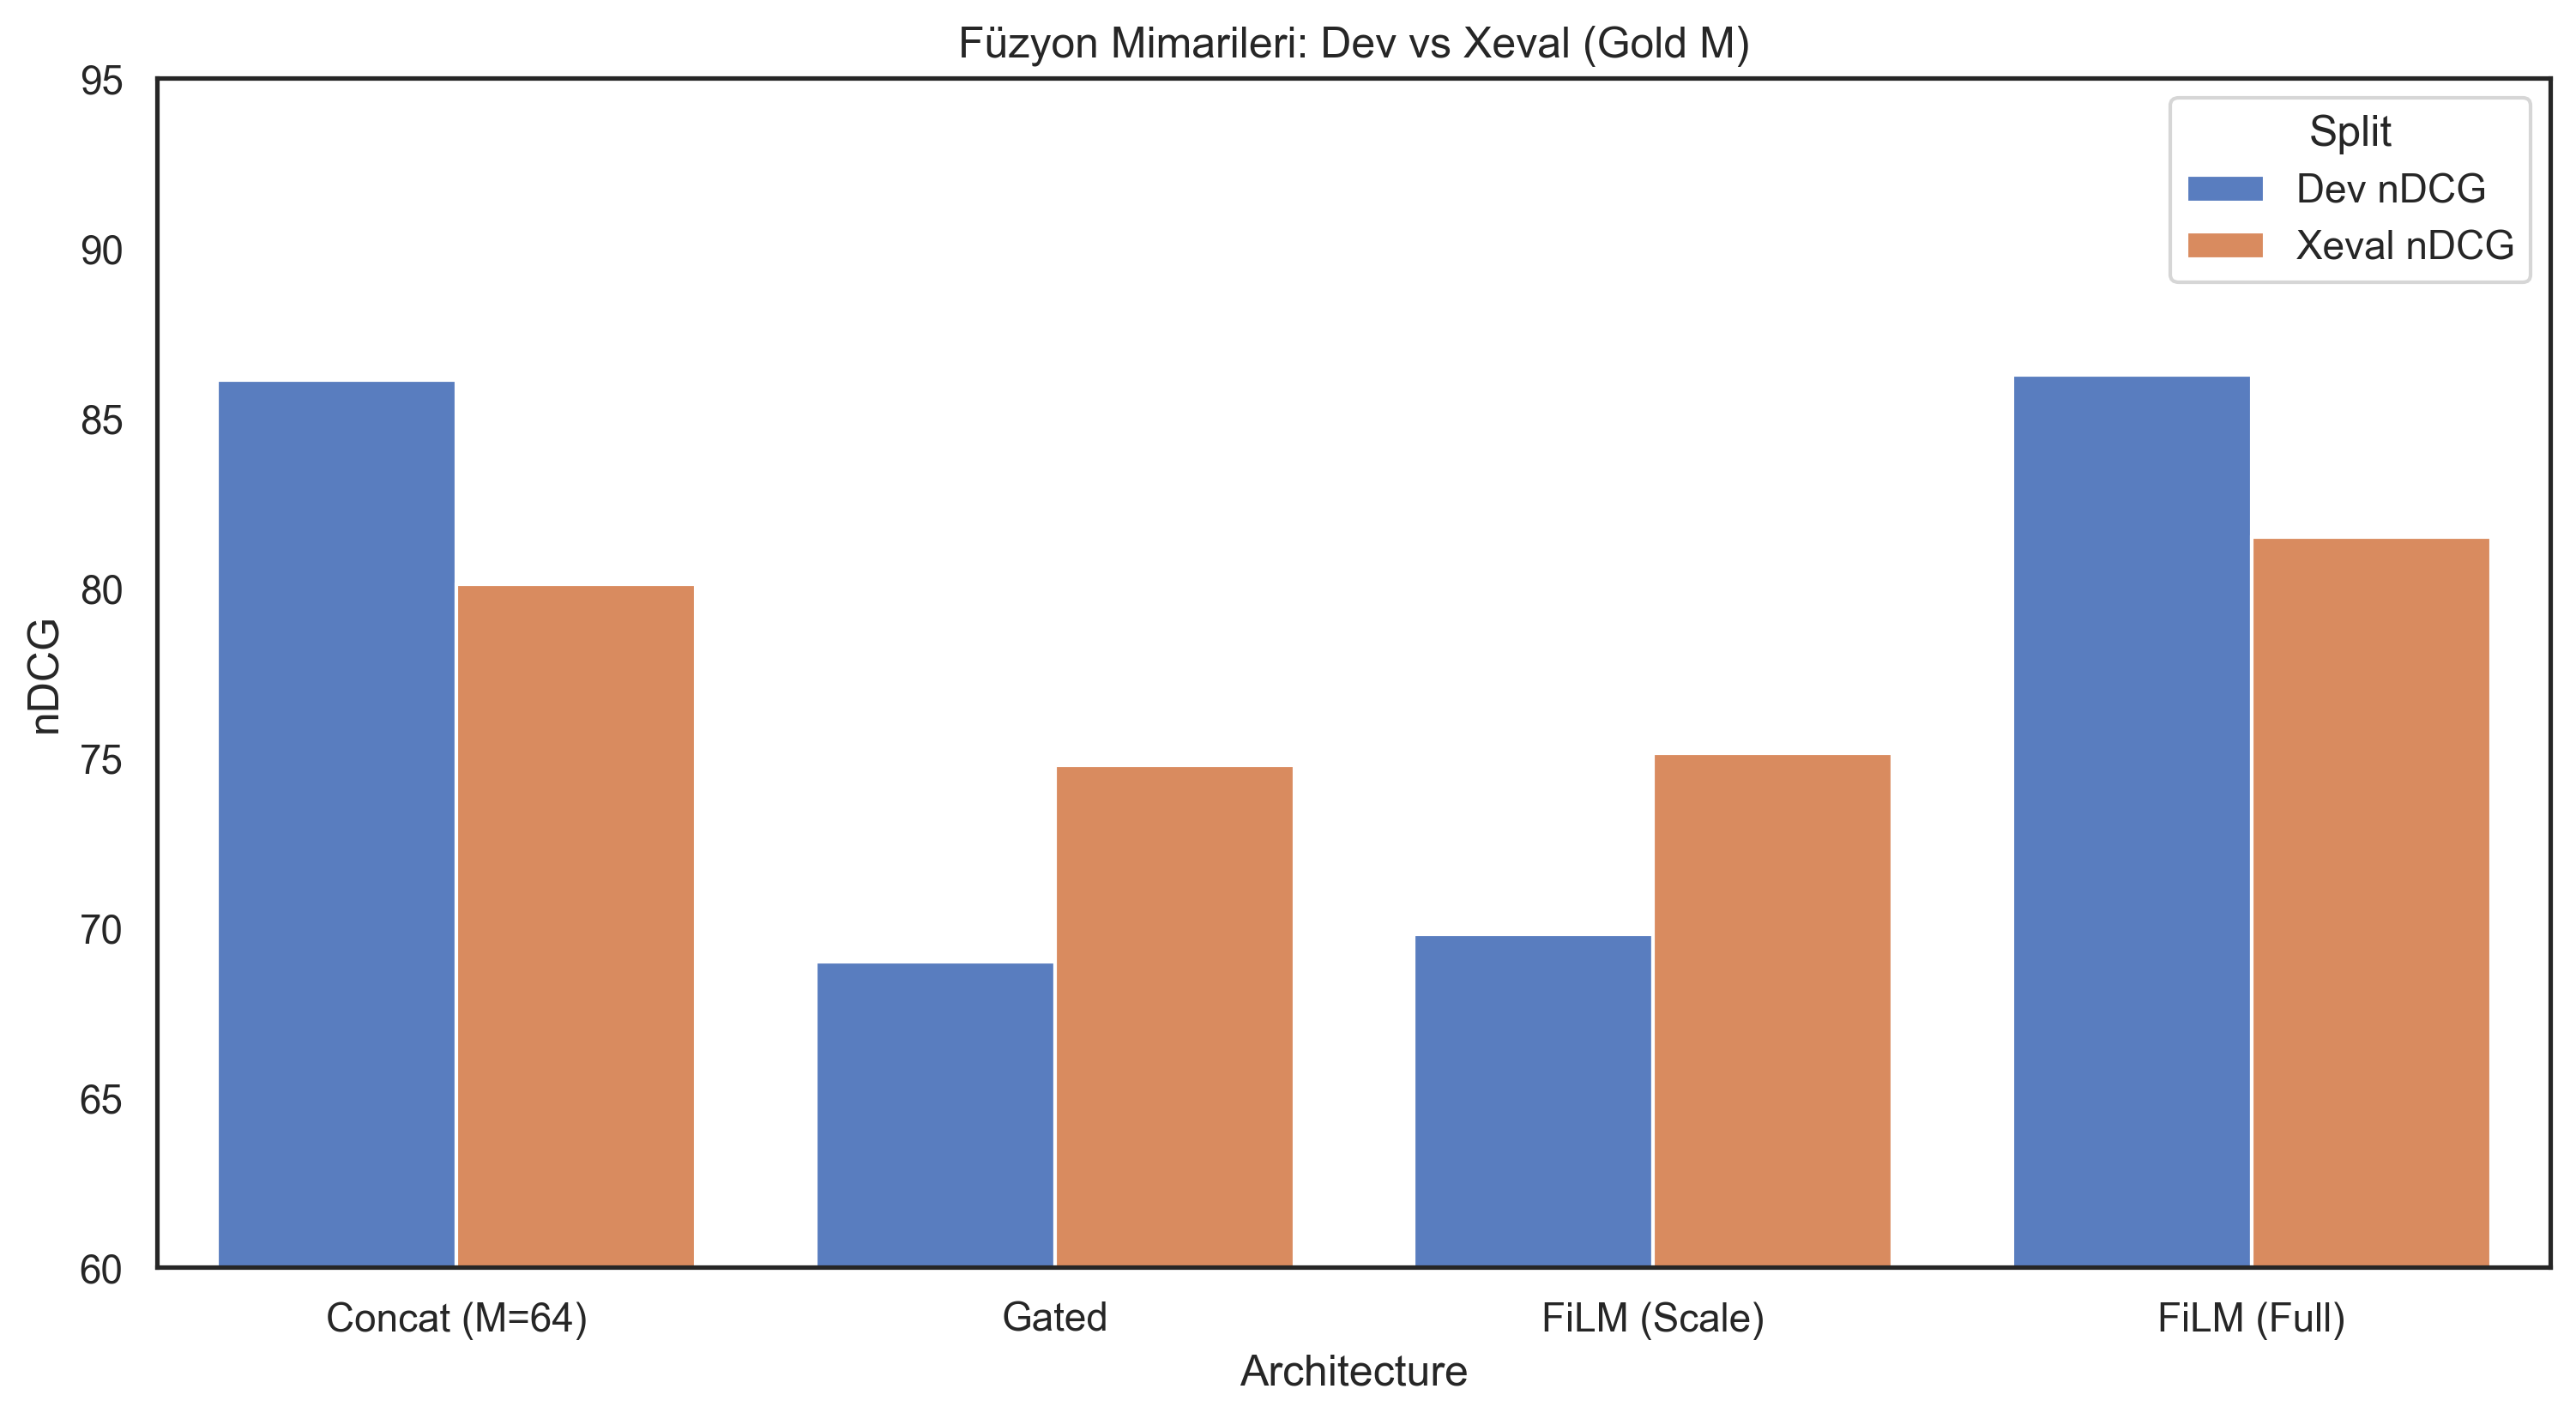

In [25]:
# --- XEVAL KIYASLAMA HÜCRESİ ---
xeval_results = []
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        # En iyi Dev skoruna sahip run'ı bul
        best_run = max(summary['runs'], key=lambda r: r['best_dev']['ndcg'])
        xeval_results.append({
            'Architecture': name,
            'Dev nDCG': best_run['best_dev']['ndcg'] * 100,
            'Xeval nDCG': best_run.get('xeval', {}).get('ndcg', 0) * 100
        })

df_comp = pd.DataFrame(xeval_results)
display(df_comp)

# Görselleştirme
df_melt = df_comp.melt(id_vars='Architecture', var_name='Split', value_name='nDCG')
plt.figure(figsize=(12, 6))
sns.barplot(data=df_melt, x='Architecture', y='nDCG', hue='Split')
plt.title("Füzyon Mimarileri: Dev vs Xeval (Gold M)")
plt.ylim(60, 95)
plt.show()
